In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [27]:
dataset = pd.read_csv('./data/Data.csv')
x = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

print(x)
print(y)

[['France' 44.0 72000.0]
 ['Spain' 27.0 48000.0]
 ['Germany' 30.0 54000.0]
 ['Spain' 38.0 61000.0]
 ['Germany' 40.0 nan]
 ['France' 35.0 58000.0]
 ['Spain' nan 52000.0]
 ['France' 48.0 79000.0]
 ['Germany' 50.0 83000.0]
 ['France' 37.0 67000.0]]
<StringArray>
['No', 'Yes', 'No', 'No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes']
Length: 10, dtype: str


In [28]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy="mean")

imputer.fit(x[:, 1:3])
x[:, 1:3] = imputer.transform(x[:, 1:3])

print(x)

[['France' 44.0 72000.0]
 ['Spain' 27.0 48000.0]
 ['Germany' 30.0 54000.0]
 ['Spain' 38.0 61000.0]
 ['Germany' 40.0 63777.77777777778]
 ['France' 35.0 58000.0]
 ['Spain' 38.77777777777778 52000.0]
 ['France' 48.0 79000.0]
 ['Germany' 50.0 83000.0]
 ['France' 37.0 67000.0]]


### 원-핫 인코딩 OneHotEncoder
보통 입력 특성 데이터(x)을 x의 0번째 열([0])에 있는 문자열 범주(['France', 'Spain', 'Germany'])를 0과 1로 구성된 여러 개의 이진(binary)열로 펼침.

만약 특성 X에 France=0, Spain=1, Germany=2 처럼 숫자를 부여해버리면, 선형 회귀나 신경망 같은 모델이 "독일(2)이 프랑스(0)보다 2배 더 크다"고 잘못 해석해 가중치를 왜곡할수 있다.

따라서 각 국가마다 독립된 열을 만들어 상호 대등한 관계로 처리함.


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

ct = ColumnTransformer(
    transformers=[("encoder", OneHotEncoder(), [0])], remainder="passthrough"
)

x = np.array(ct.fit_transform(x))

print(x)

[[0.0 1.0 0.0 0.0 44.0 72000.0]
 [1.0 0.0 0.0 1.0 27.0 48000.0]
 [1.0 0.0 1.0 0.0 30.0 54000.0]
 [1.0 0.0 0.0 1.0 38.0 61000.0]
 [1.0 0.0 1.0 0.0 40.0 63777.77777777778]
 [0.0 1.0 0.0 0.0 35.0 58000.0]
 [1.0 0.0 0.0 1.0 38.77777777777778 52000.0]
 [0.0 1.0 0.0 0.0 48.0 79000.0]
 [1.0 0.0 1.0 0.0 50.0 83000.0]
 [0.0 1.0 0.0 0.0 37.0 67000.0]]


### 레이블인코딩 LabelEncoder
1차원 배열인 타깃 y(예: ['No', 'Yes', 'No'])를 단순 정수([0, 1, 0])러 변환함.

머신러닝 모델의 정답(타깃 레이블)은 컴퓨터가 계산할 수 있는 숫자 형태 (0, 1, 2 ...) 여야 함. 왜냐하면 컴퓨터는 숫자로만 이해를 함.

그래서 scikit-learn 공식 문서에서도 LabelEncoder는 독립변수 X 가 아닌 타깃 레이블 u를 변환할 때만 사용하도록 권장을 하고 있음.



In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

print(y)

[0 1 0 0 1 1 0 1 0 1]


### 머신러닝 모의고사 치리기

전체 데이터륾 ㅓ신러닝 모델의 학습용 데이터 (Train set)와 모델의 성능을 평가하기 위한 테스트용 데이터(Test set)로 분할하는 코드.

모의고사 문제와 답으로 공부한 뒤 실전 시험 문제로 점수를 매기듯, 데이터를 나누어 모델의 과적합(Overfitting)을 방지하고, 정확한 일반화 성능을 확인하기 위해 머신러닝 파이프라인에서 필수로 거치는 단계.

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)은 톡립변수 x와 종속변수 y (특성과 정답 라벨)를 입력받아, 총 4개의 세트로 분할하여 언패킹(Unpacking)함.

test_size = 0.2 전체 데이터중 20%를 테스트용, 나머지 80%를 학습용으로 배정함.

random_state = 1 데이터를 섞을 때 사용할 난수 시드(Seed)값. 이 값을 특정 정수로 고정해 두면, 코드를 언제 다시 실행하더라도 항상 동일하게 데이터가 분할되어 실험 재현성(Reproducibility)이 보장됩니다.

- x_train(문제집)
    - 컴퓨터 한테 보여주는 강아지 사진

- y_train(해답지)
    - 그 사진 밑에 적힌 "이건 강아지 맞음(1), "이건 고양이임(0)" 이라는 진짜 정답

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1)

print("---모의고사 문제집---")
print(x_train)
print("---실전 시험 문제지---")
print(x_test)
print("---모의고사 해답지---")
print(y_train)
print("---실전 채점용 정답지---")
print(y_test)

---모의고사 문제집---
[[1.0 0.0 1.0 0.0 40.0 63777.77777777778]
 [0.0 1.0 0.0 0.0 44.0 72000.0]
 [1.0 0.0 0.0 1.0 38.0 61000.0]
 [1.0 0.0 0.0 1.0 27.0 48000.0]
 [0.0 1.0 0.0 0.0 48.0 79000.0]
 [1.0 0.0 1.0 0.0 50.0 83000.0]
 [0.0 1.0 0.0 0.0 35.0 58000.0]]
---실전 시험 문제지---
[[1.0 0.0 1.0 0.0 30.0 54000.0]
 [0.0 1.0 0.0 0.0 37.0 67000.0]
 [1.0 0.0 0.0 1.0 38.77777777777778 52000.0]]
---모의고사 해답지---
[1 0 0 1 1 0 1]
---실전 채점용 정답지---
[0 1 0]


### 표준화
표준화 공식을 사용해, x_train과 x_test의 숫자 데이터(나이, 연봉)를 비슷한 체급으로 줄여주는 코드.

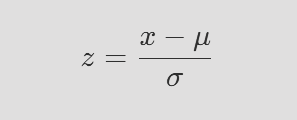


In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train[:, 3:] = sc.fit_transform(x_train[:, 3:])
x_test[:, 3:] = sc.transform(x_test[:, 3:])

print("--- 문제집 ---")
print(x_train)
print("--- 시험 문제지 ---")
print(x_test)

[[1.0 0.0 1.0 -0.6324555320336759 -0.03891021128204815
  -0.22960023388015172]
 [0.0 1.0 0.0 -0.6324555320336759 0.5058327466666259 0.491205348846628]
 [1.0 0.0 0.0 1.5811388300841895 -0.31128169025638514 -0.4731156334500102]
 [1.0 0.0 0.0 1.5811388300841895 -1.8093248246152385 -1.612767703436946]
 [0.0 1.0 0.0 -0.6324555320336759 1.0505757046152997 1.1048641557626706]
 [1.0 0.0 1.0 -0.6324555320336759 1.3229471835896367 1.4555263311432662]
 [0.0 1.0 0.0 -0.6324555320336759 -0.7198389087178906 -0.7361122649854568]]
